# Diabetes dataset

In [13]:
# Librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [14]:
# Chargement des données
diabet = pd.read_csv('diabetes_pred.csv')
diabet.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494,0
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281,0
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873,1
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868,0
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789,0


In [15]:
diabet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               1000 non-null   int64  
 1   Glucose                   1000 non-null   float64
 2   BloodPressure             1000 non-null   float64
 3   SkinThickness             1000 non-null   float64
 4   Insulin                   1000 non-null   float64
 5   BMI                       1000 non-null   float64
 6   DiabetesPedigreeFunction  1000 non-null   float64
 7   Age                       1000 non-null   float64
 8   Diagnosis                 1000 non-null   int64  
dtypes: float64(7), int64(2)
memory usage: 70.4 KB


In [16]:
diabet.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Diagnosis
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,1.771000,99.440607,72.179837,23.278316,84.582679,25.433600,0.449383,43.281798,0.30600
std,1.354398,19.470730,13.882017,1.173807,74.872733,3.690223,0.199334,14.465398,0.46106
min,0.000000,30.571402,31.401487,19.369987,-165.310033,13.548818,0.100037,-0.979804,0.00000
25%,1.000000,86.145927,62.795447,22.501591,35.076535,23.022715,0.283376,33.518451,0.00000
50%,2.000000,99.458362,71.909588,23.275225,84.442232,25.455649,0.448219,43.634273,0.00000
75%,3.000000,113.264556,82.082660,24.052022,134.267842,27.972184,0.619158,53.098446,1.00000
max,8.000000,161.238939,110.723715,26.917654,317.701852,36.324598,0.799654,90.573782,1.00000


In [17]:
# Filtrer pour garder uniquement les valeurs cohérentes
diabet = diabet[(diabet['Insulin'] >= 0) & (diabet['Age'] >= 0)]

# Vérifier combien de lignes il reste
print(diabet.shape)

(871, 9)


In [18]:
diabet.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Diagnosis                   0
dtype: int64

In [19]:
diabet.duplicated().sum()

np.int64(0)

In [20]:
# Selection des features 
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI','DiabetesPedigreeFunction', 'Age']
X = diabet[features]
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,115.863387,56.410731,24.336736,94.385783,26.455940,0.272682,20.100494
1,2,92.490122,70.615520,23.443591,138.652426,23.910167,0.665160,44.912281
2,1,88.141469,63.262618,23.404364,149.358082,21.948250,0.676022,48.247873
3,2,108.453101,67.793632,20.751580,108.751638,24.209304,0.289636,42.749868
4,1,127.849443,94.725685,22.603078,25.269987,32.997477,0.601315,32.797789
...,...,...,...,...,...,...,...,...
995,1,103.496355,41.059401,24.930299,43.675978,25.846062,0.455884,19.905419
996,1,60.714150,64.082842,24.689064,111.562745,19.464280,0.250560,44.421874
997,0,97.597727,64.122312,22.140339,108.138552,22.733052,0.761463,58.949800
998,0,66.775137,55.908797,24.885274,219.521484,31.819187,0.382877,46.928923


In [21]:
# Mise à l'échelle
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [22]:
# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nExplained variance ratio (PC1, PC2):", pca.explained_variance_ratio_)


Explained variance ratio (PC1, PC2): [0.15066723 0.14275307]


In [23]:
# L'importance des features de chaque PC
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

loadings_df = pd.DataFrame(
    loadings,
    index=features,
    columns=['PC1', 'PC2']
)

print(loadings_df.round(3))

                            PC1    PC2
Pregnancies               0.493 -0.070
Glucose                   0.110 -0.294
BloodPressure             0.493  0.421
SkinThickness            -0.492  0.262
Insulin                   0.044  0.737
BMI                      -0.320  0.264
DiabetesPedigreeFunction  0.147 -0.405
Age                       0.584  0.172


In [26]:
# Calcul des contributions des variables
contributions = pca.components_**2 * 100

contributions_df = pd.DataFrame(
    contributions.T,
    index=features,
    columns=['PC1', 'PC2']
)

print(contributions_df.round(2))

                            PC1    PC2
Pregnancies               20.16   0.43
Glucose                    1.00   7.55
BloodPressure             20.10  15.52
SkinThickness             20.04   6.00
Insulin                    0.16  47.45
BMI                        8.50   6.11
DiabetesPedigreeFunction   1.80  14.35
Age                       28.24   2.59


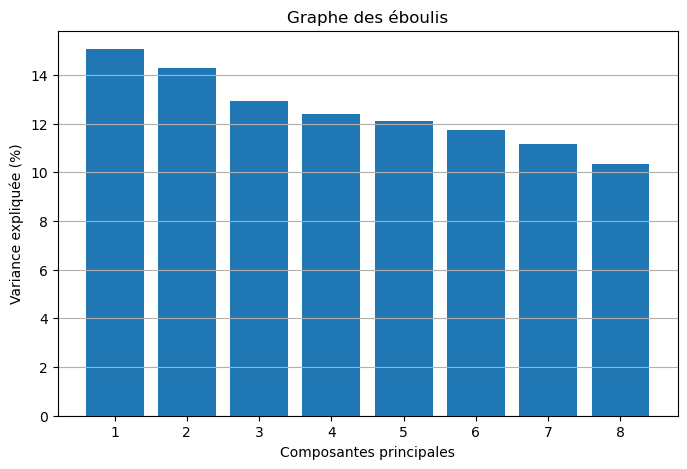

In [30]:
# Variance expliquée par chaque composante
pca_full = PCA()
pca_full.fit(X_scaled)

plt.figure(figsize=(8, 5))

plt.bar(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_ * 100
)

plt.xlabel("Composantes principales")
plt.ylabel("Variance expliquée (%)")
plt.title("Graphe des éboulis")
plt.xticks(range(1, 9))
plt.grid(axis='y')
plt.show()

In [31]:
variance = pca_full.explained_variance_ratio_ * 100
variance_cumulee = np.cumsum(variance)

for i, (v, vc) in enumerate(zip(variance, variance_cumulee), 1):
    print(f"PC{i} : {v:.2f}% | Cumul : {vc:.2f}%")

PC1 : 15.07% | Cumul : 15.07%
PC2 : 14.28% | Cumul : 29.34%
PC3 : 12.91% | Cumul : 42.26%
PC4 : 12.41% | Cumul : 54.67%
PC5 : 12.10% | Cumul : 66.77%
PC6 : 11.73% | Cumul : 78.50%
PC7 : 11.17% | Cumul : 89.67%
PC8 : 10.33% | Cumul : 100.00%


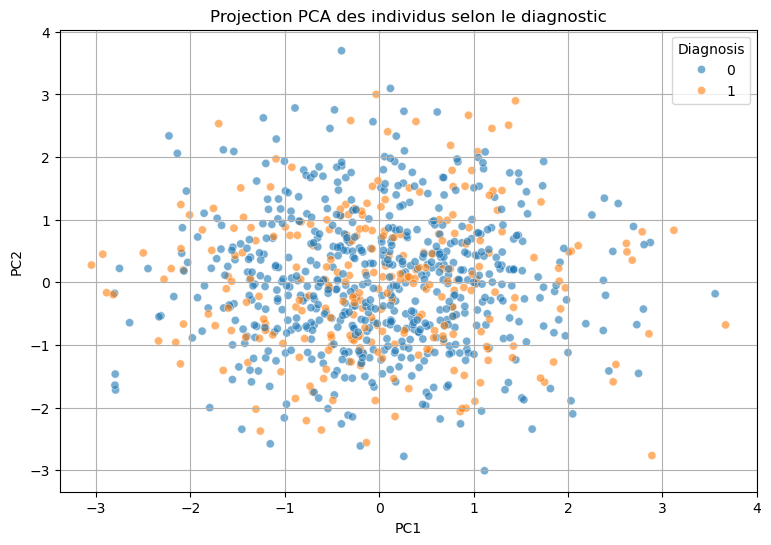

In [28]:
# Projection des individus

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=diabet['Diagnosis'],
    alpha=0.6,
    s=35
)

plt.title("Projection PCA des individus selon le diagnostic")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()

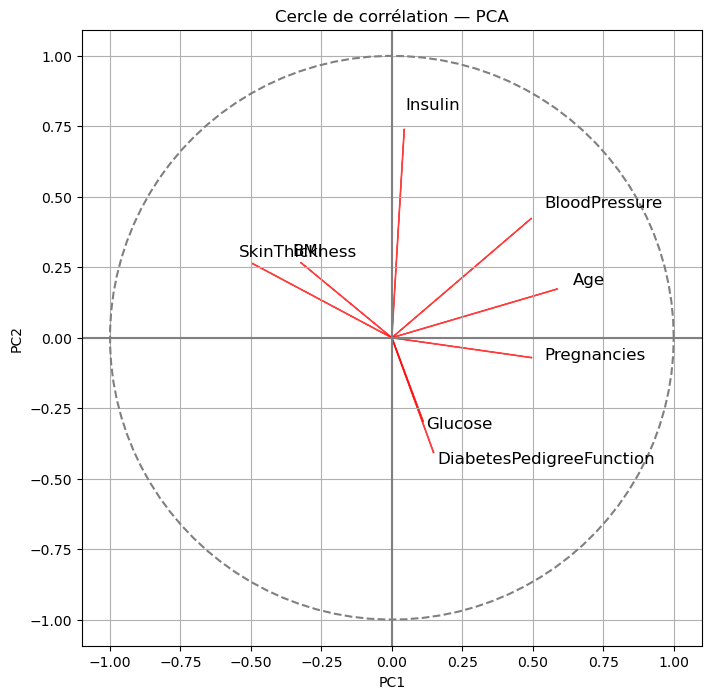

In [25]:
# Cercle de corrélation (projection des variables)

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

plt.figure(figsize=(8,8))
plt.axhline(0, color='grey')
plt.axvline(0, color='grey')

theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), linestyle='--', color='grey')

for i, feature in enumerate(features):
    x = loadings[i, 0]
    y = loadings[i, 1]
    plt.arrow(0, 0, x, y, color='red', alpha=0.7)
    plt.text(x*1.1, y*1.1, feature, fontsize=12)

plt.title("Cercle de corrélation — PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.axis("equal")
plt.grid(True)
plt.show()